In [2]:
from pathlib import Path
import random

import numpy as np
import pandas as pd

DATA_PATH = Path("bank-additional.csv")
SPLIT_PATH = Path("results/dataset_split.csv")
BASE_SEED = 31060

seed_names = (
    "python", "numpy", "torch", "holdout", "outer_cv",
    "inner_cv", "early_stop", "random_search", "bootstrap",
)
seed_values = np.random.SeedSequence(BASE_SEED).generate_state(len(seed_names))
SEEDS = dict(zip(seed_names, map(int, seed_values)))

random.seed(SEEDS["python"])
np.random.seed(SEEDS["numpy"])

split_table = pd.read_csv(SPLIT_PATH)

assert len(split_table) == 4119
assert split_table["row_id"].is_unique
assert set(split_table["row_id"]) == set(range(4119))
assert set(split_table["split"]) == {"development", "independent_test"}

dev_row_ids = (
    split_table.loc[split_table["split"].eq("development"), "row_id"]
    .sort_values()
    .to_numpy()
)
dev_row_set = set(dev_row_ids)

# CSV'de 0. satır başlık, 1. satır ise row_id = 0 olan kayıttır.
development = pd.read_csv(
    DATA_PATH,
    sep=";",
    skiprows=lambda line: line != 0 and (line - 1) not in dev_row_set,
)
assert len(development) == len(dev_row_ids) == 3296
development.index = pd.Index(dev_row_ids, name="row_id")

X_dev = development.drop(columns=["duration", "y"])
y_dev = development["y"].map({"no": 0, "yes": 1})

assert X_dev.shape == (3296, 19)
assert y_dev.notna().all()
assert y_dev.value_counts().to_dict() == {0: 2937, 1: 359}

print("Temel seed:", BASE_SEED)
print("Development boyutu:", X_dev.shape)
print("Sınıf sayıları:", y_dev.value_counts().sort_index().to_dict())

Temel seed: 31060
Development boyutu: (3296, 19)
Sınıf sayıları: {0: 2937, 1: 359}


In [3]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    MinMaxScaler,
    OneHotEncoder,
    RobustScaler,
    StandardScaler,
)

NUMERIC_COLUMNS = X_dev.select_dtypes(include="number").columns.tolist()
CATEGORICAL_COLUMNS = [
    column for column in X_dev.columns if column not in NUMERIC_COLUMNS
]
SCALERS = {
    "standard": StandardScaler,
    "minmax": MinMaxScaler,
    "robust": RobustScaler,
}


def mask_pdays_sentinel(frame):
    result = frame.copy()
    result["pdays"] = result["pdays"].mask(result["pdays"].eq(999))
    return result


def previous_contact_flag(frame):
    return frame["pdays"].eq(999).astype("float32").to_frame("pdays_never_contacted")


class PercentileClipper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.lower_ = X.quantile(0.01).fillna(-np.inf)
        self.upper_ = X.quantile(0.99).fillna(np.inf)
        return self

    def transform(self, X):
        return X.clip(lower=self.lower_, upper=self.upper_, axis="columns")


def make_preprocessor(scaler="standard", clip_outliers=False):
    numeric_pipeline = Pipeline([
        ("mask_pdays", FunctionTransformer(mask_pdays_sentinel)),
        ("clip", PercentileClipper() if clip_outliers else "passthrough"),
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", SCALERS[scaler]()),
    ])

    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_COLUMNS),
        ("categorical", categorical_pipeline, CATEGORICAL_COLUMNS),
        ("pdays_flag", FunctionTransformer(previous_contact_flag), ["pdays"]),
    ])


print("Sayısal sütun:", len(NUMERIC_COLUMNS))
print("Kategorik sütun:", len(CATEGORICAL_COLUMNS))
print("Ön işleyici tanımlandı.")

Sayısal sütun: 9
Kategorik sütun: 10
Ön işleyici tanımlandı.


In [4]:
from copy import deepcopy
from time import perf_counter

import torch
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.set_num_threads(1)


class BankMLP(nn.Module):
    def __init__(self, input_dim, hidden_layers, activation, dropout):
        super().__init__()
        activation_class = {"relu": nn.ReLU, "tanh": nn.Tanh}[activation]
        layers = []
        previous_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.extend([nn.Linear(previous_dim, hidden_dim), activation_class()])
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            previous_dim = hidden_dim

        layers.append(nn.Linear(previous_dim, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, features):
        return self.network(features).squeeze(-1)


def make_optimizer(model, config):
    options = {"lr": config["lr"], "weight_decay": config["weight_decay"]}
    if config["optimizer"] == "sgd":
        return torch.optim.SGD(model.parameters(), momentum=0.9, **options)

    optimizer_class = {"adam": torch.optim.Adam, "adamw": torch.optim.AdamW}
    return optimizer_class[config["optimizer"]](model.parameters(), **options)


def split_early_stop(y_train, split_seed):
    return train_test_split(
        y_train.index.to_numpy(),
        test_size=0.15,
        stratify=y_train.to_numpy(),
        random_state=split_seed,
    )


def make_tensors(preprocessor, X, y):
    features = torch.as_tensor(preprocessor.transform(X), dtype=torch.float32)
    labels = torch.as_tensor(y.to_numpy(), dtype=torch.float32)
    return features, labels


def train_mlp(X_train, y_train, config, *, split_seed, model_seed, max_epochs=150):
    started_at = perf_counter()
    torch.manual_seed(model_seed)

    fit_ids, monitor_ids = split_early_stop(y_train, split_seed)
    X_fit, y_fit = X_train.loc[fit_ids], y_train.loc[fit_ids]
    X_monitor, y_monitor = X_train.loc[monitor_ids], y_train.loc[monitor_ids]

    preprocessor = make_preprocessor(config["scaler"], config["clip_outliers"])
    preprocessor.fit(X_fit)

    fit_features, fit_labels = make_tensors(preprocessor, X_fit, y_fit)
    monitor_features, monitor_labels = make_tensors(
        preprocessor, X_monitor, y_monitor
    )

    model = BankMLP(
        input_dim=fit_features.shape[1],
        hidden_layers=config["hidden_layers"],
        activation=config["activation"],
        dropout=config["dropout"],
    )
    loader = DataLoader(
        TensorDataset(fit_features, fit_labels),
        batch_size=config["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(model_seed),
    )
    criterion = nn.BCEWithLogitsLoss()
    optimizer = make_optimizer(model, config)

    scheduler = None
    if config["scheduler"]:
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=0.5, patience=5, min_lr=1e-5
        )

    best_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    stop_reason = "epoch_limit"
    history = []

    for epoch in range(1, max_epochs + 1):
        model.train()
        total_train_loss = 0.0
        epoch_lr = optimizer.param_groups[0]["lr"]

        for batch_features, batch_labels in loader:
            optimizer.zero_grad()
            loss = criterion(model(batch_features), batch_labels)
            if not torch.isfinite(loss).item():
                raise FloatingPointError(f"Epoch {epoch}: eğitim kaybı sonlu değil.")
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * len(batch_labels)

        model.eval()
        with torch.inference_mode():
            monitor_loss = criterion(model(monitor_features), monitor_labels).item()

        if not np.isfinite(monitor_loss):
            raise FloatingPointError(f"Epoch {epoch}: doğrulama kaybı sonlu değil.")

        if scheduler is not None:
            scheduler.step(monitor_loss)

        history.append({
            "epoch": epoch,
            "train_bce": total_train_loss / len(fit_labels),
            "monitor_bce": monitor_loss,
            "learning_rate": epoch_lr,
            "next_learning_rate": optimizer.param_groups[0]["lr"],
        })

        if monitor_loss < best_loss:
            best_loss = monitor_loss
            best_epoch = epoch
            best_weights = deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= 15:
            stop_reason = "early_stopping"
            break

    model.load_state_dict(best_weights)
    model.eval()

    return {
        "model": model,
        "preprocessor": preprocessor,
        "history": pd.DataFrame(history),
        "best_epoch": best_epoch,
        "stopped_epoch": len(history),
        "best_monitor_bce": best_loss,
        "stop_reason": stop_reason,
        "duration_seconds": perf_counter() - started_at,
        "parameter_count": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "input_dim": fit_features.shape[1],
        "fit_size": len(fit_ids),
        "monitor_size": len(monitor_ids),
    }


def predict_proba_mlp(trained, X):
    features = torch.as_tensor(
        trained["preprocessor"].transform(X), dtype=torch.float32
    )
    trained["model"].eval()
    with torch.inference_mode():
        return torch.sigmoid(trained["model"](features)).numpy()


print("PyTorch:", torch.__version__)
print("MLP ve eğitim döngüsü tanımlandı.")

PyTorch: 2.14.1+cpu
MLP ve eğitim döngüsü tanımlandı.


In [5]:
m1_config = {
    "optimizer": "adamw",
    "hidden_layers": (32,),
    "activation": "relu",
    "lr": 0.001,
    "weight_decay": 1e-4,
    "batch_size": 64,
    "scaler": "standard",
    "dropout": 0.0,
    "clip_outliers": False,
    "scheduler": True,
}

smoke_run = train_mlp(
    X_dev,
    y_dev,
    m1_config,
    split_seed=SEEDS["early_stop"],
    model_seed=SEEDS["torch"],
    max_epochs=3,
)

probabilities = predict_proba_mlp(smoke_run, X_dev.iloc[:5])

assert len(smoke_run["history"]) == 3
assert smoke_run["fit_size"] + smoke_run["monitor_size"] == len(X_dev)
assert np.isfinite(probabilities).all()
assert ((0 <= probabilities) & (probabilities <= 1)).all()

print("Ağırlık eğitimi:", smoke_run["fit_size"])
print("Erken durdurma izlemesi:", smoke_run["monitor_size"])
print("One-hot sonrası girdi sayısı:", smoke_run["input_dim"])
print("Öğrenilebilir parametre sayısı:", smoke_run["parameter_count"])
display(smoke_run["history"].round(6))

Ağırlık eğitimi: 2801
Erken durdurma izlemesi: 495
One-hot sonrası girdi sayısı: 62
Öğrenilebilir parametre sayısı: 2049


,epoch,train_bce,monitor_bce,learning_rate,next_learning_rate
0,1,0.539520,0.376544,0.001,0.001
1,2,0.317070,0.291229,0.001,0.001
2,3,0.283811,0.281275,0.001,0.001


In [6]:
import json

manual_configs = {
    "M1": dict(m1_config),
    "M2": {**m1_config, "optimizer": "adam"},
    "M3": {**m1_config, "optimizer": "sgd"},
    "M4": {**m1_config, "scaler": "minmax"},
    "M5": {**m1_config, "hidden_layers": (64, 32)},
    "M6": {**m1_config, "scheduler": False},
}

random_space = {
    "hidden_layers": [(16,), (32,), (64,), (64, 32), (128, 64)],
    "activation": ["relu", "tanh"],
    "weight_decay": [0.0, 1e-5, 1e-4, 1e-3],
    "batch_size": [32, 64, 128],
    "scaler": ["standard", "minmax", "robust"],
    "dropout": [0.0, 0.2],
    "clip_outliers": [False, True],
}
lr_bounds = {
    "sgd": (1e-3, 1e-1),
    "adam": (1e-4, 1e-2),
    "adamw": (1e-4, 1e-2),
}

rng = np.random.default_rng(SEEDS["random_search"])
random_configs = {}

for optimizer, (low, high) in lr_bounds.items():
    for _ in range(2):
        sampled_options = {
            name: options[int(rng.integers(len(options)))]
            for name, options in random_space.items()
        }
        candidate_id = f"R{len(random_configs) + 1}"
        random_configs[candidate_id] = {
            "optimizer": optimizer,
            "lr": float(10 ** rng.uniform(np.log10(low), np.log10(high))),
            **sampled_options,
            "scheduler": True,
        }

assert len(manual_configs) == len(random_configs) == 6
assert pd.Series([
    config["optimizer"] for config in random_configs.values()
]).value_counts().to_dict() == {"sgd": 2, "adam": 2, "adamw": 2}

training_settings = {
    "base_seed": BASE_SEED,
    "seeds": SEEDS,
    "outer_folds": 3,
    "inner_folds": 3,
    "max_epochs": 150,
    "early_stop_fraction": 0.15,
    "early_stop_patience": 15,
    "scheduler": {"mode": "min", "factor": 0.5, "patience": 5, "min_lr": 1e-5},
    "sgd_momentum": 0.9,
    "selection_metric": "average_precision",
    "classification_threshold": 0.5,
}

config_dir = Path("configs")
config_dir.mkdir(exist_ok=True)

config_files = {
    "manual_candidates.json": manual_configs,
    "random_candidates.json": random_configs,
    "random_search_space.json": {
        **random_space,
        "lr_bounds": lr_bounds,
        "lr_sampling": "log_uniform",
        "candidates_per_optimizer": 2,
        "scheduler": True,
    },
    "training_settings.json": training_settings,
}

for filename, payload in config_files.items():
    (config_dir / filename).write_text(
        json.dumps(payload, indent=2) + "\n", encoding="utf-8"
    )

candidate_table = pd.DataFrame.from_dict(
    {**manual_configs, **random_configs}, orient="index"
).rename_axis("candidate")

print(f"{len(manual_configs)} manuel + {len(random_configs)} otomatik aday")
display(candidate_table)

6 manuel + 6 otomatik aday


,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,clip_outliers,scheduler
candidate,,,,,,,,,,
M1,adamw,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,True
M2,adam,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,True
M3,sgd,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,True
M4,adamw,"(32,)",relu,0.001000,0.00010,64,minmax,0.0,False,True
M5,adamw,"(64, 32)",relu,0.001000,0.00010,64,standard,0.0,False,True
M6,adamw,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,False
R1,sgd,"(64,)",relu,0.015779,0.00000,128,minmax,0.2,False,True
R2,sgd,"(32,)",tanh,0.098376,0.00010,64,minmax,0.0,False,True
R3,adam,"(64, 32)",relu,0.006425,0.00001,128,minmax,0.0,False,True


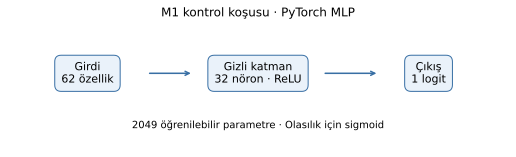

In [7]:
import matplotlib.pyplot as plt
from IPython.display import SVG, display

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)
svg_path = figures_dir / "mlp_m1_architecture.svg"

fig, ax = plt.subplots(figsize=(9, 2.3))
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis("off")

nodes = [
    (0.16, f"Girdi\n{smoke_run['input_dim']} özellik"),
    (0.50, f"Gizli katman\n{m1_config['hidden_layers'][0]} nöron · ReLU"),
    (0.84, "Çıkış\n1 logit"),
]

for x, label in nodes:
    ax.text(
        x, 0.60, label, ha="center", va="center", fontsize=11,
        bbox={"boxstyle": "round,pad=0.6", "facecolor": "#EAF2FA",
              "edgecolor": "#386FA4"},
    )

for start, end in [(0.28, 0.37), (0.63, 0.74)]:
    ax.annotate(
        "", xy=(end, 0.60), xytext=(start, 0.60),
        arrowprops={"arrowstyle": "->", "color": "#386FA4", "lw": 1.5},
    )

ax.set_title("M1 kontrol koşusu · PyTorch MLP")
ax.text(
    0.5, 0.17,
    f"{smoke_run['parameter_count']} öğrenilebilir parametre · Olasılık için sigmoid",
    ha="center", fontsize=10,
)
with plt.rc_context({"svg.fonttype": "none"}):
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename=str(svg_path)))

In [8]:
from sklearn.model_selection import StratifiedKFold

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

OUTER_FOLDS = 3
INNER_FOLDS = 3


def fold_seed(base, outer_fold, inner_fold=0):
    sequence = np.random.SeedSequence([base, outer_fold, inner_fold])
    return int(sequence.generate_state(1)[0])


input_groups = X_dev.groupby(
    NUMERIC_COLUMNS + CATEGORICAL_COLUMNS, dropna=False, sort=False
).ngroup()


def shared_input_groups(train_ids, evaluation_ids):
    return len(
        set(input_groups.loc[train_ids])
        & set(input_groups.loc[evaluation_ids])
    )


def make_inner_plan(train_ids, outer_fold):
    train_ids = np.asarray(train_ids)
    labels = y_dev.loc[train_ids]
    splitter = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=fold_seed(SEEDS["inner_cv"], outer_fold),
    )

    return [
        {
            "inner_fold": inner_fold,
            "train_ids": train_ids[train_pos],
            "validation_ids": train_ids[val_pos],
            "split_seed": fold_seed(SEEDS["early_stop"], outer_fold, inner_fold),
            "model_seed": fold_seed(SEEDS["torch"], outer_fold, inner_fold),
        }
        for inner_fold, (train_pos, val_pos) in enumerate(
            splitter.split(train_ids, labels), start=1
        )
    ]


outer_splitter = StratifiedKFold(
    n_splits=OUTER_FOLDS,
    shuffle=True,
    random_state=SEEDS["outer_cv"],
)
development_ids = X_dev.index.to_numpy()
cv_plan = {}
split_audit_rows = []
fold_assignments = []

for outer_fold, (train_pos, eval_pos) in enumerate(
    outer_splitter.split(X_dev, y_dev), start=1
):
    outer_train_ids = development_ids[train_pos]
    outer_eval_ids = development_ids[eval_pos]
    inner_plan = make_inner_plan(outer_train_ids, outer_fold)

    cv_plan[outer_fold] = {
        "train_ids": outer_train_ids,
        "evaluation_ids": outer_eval_ids,
        "inner_plan": inner_plan,
    }

    for fold in inner_plan:
        train_ids = fold["train_ids"]
        val_ids = fold["validation_ids"]
        fit_ids, monitor_ids = split_early_stop(
            y_dev.loc[train_ids], fold["split_seed"]
        )

        assert set(train_ids).isdisjoint(val_ids)
        assert set(fit_ids).isdisjoint(monitor_ids)
        assert (set(fit_ids) | set(monitor_ids) | set(val_ids)).isdisjoint(
            outer_eval_ids
        )

        split_audit_rows.append({
            "outer_fold": outer_fold,
            "inner_fold": fold["inner_fold"],
            "fit_rows": len(fit_ids),
            "monitor_rows": len(monitor_ids),
            "inner_validation_rows": len(val_ids),
            "outer_evaluation_rows": len(outer_eval_ids),
            "shared_fit_monitor_groups": shared_input_groups(fit_ids, monitor_ids),
            "shared_inner_groups": shared_input_groups(train_ids, val_ids),
            "shared_outer_groups": shared_input_groups(outer_train_ids, outer_eval_ids),
            "split_seed": fold["split_seed"],
            "model_seed": fold["model_seed"],
        })

        for role, ids in [
            ("fit", fit_ids),
            ("early_stop_monitor", monitor_ids),
            ("inner_validation", val_ids),
            ("outer_evaluation", outer_eval_ids),
        ]:
            fold_assignments.append(pd.DataFrame({
                "outer_fold": outer_fold,
                "inner_fold": fold["inner_fold"],
                "row_id": ids,
                "role": role,
            }))

cv_split_audit = pd.DataFrame(split_audit_rows)
cv_split_audit.to_csv(results_dir / "cv_split_audit.csv", index=False)
pd.concat(fold_assignments, ignore_index=True).to_csv(
    results_dir / "cv_fold_assignments.csv", index=False
)

assert len(cv_split_audit) == 9
display(cv_split_audit)

,outer_fold,inner_fold,fit_rows,monitor_rows,inner_validation_rows,outer_evaluation_rows,shared_fit_monitor_groups,shared_inner_groups,shared_outer_groups,split_seed,model_seed
0,1,1,1244,220,733,1099,0,5,4,2443564505,1314507345
1,1,2,1245,220,732,1099,0,6,4,4264447242,2374325939
2,1,3,1245,220,732,1099,2,7,4,1775488591,3339538789
3,2,1,1244,220,733,1099,1,3,5,957589713,3966730529
4,2,2,1245,220,732,1099,0,3,5,3032383306,3738213568
5,2,3,1245,220,732,1099,1,4,5,507777934,484416447
6,3,1,1245,220,733,1098,2,3,5,3979027433,1306350192
7,3,2,1245,220,733,1098,1,5,5,3535130977,1760881204
8,3,3,1246,220,732,1098,0,4,5,1318451048,966219301


In [9]:
import warnings

from sklearn.metrics import average_precision_score


def run_inner_search(inner_plan, candidates, *, method, outer_fold):
    records = []
    epoch_logs = []

    for candidate_id, config in candidates.items():
        for fold in inner_plan:
            train_ids = fold["train_ids"]
            val_ids = fold["validation_ids"]

            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                trained = train_mlp(
                    X_dev.loc[train_ids],
                    y_dev.loc[train_ids],
                    config,
                    split_seed=fold["split_seed"],
                    model_seed=fold["model_seed"],
                )
                probabilities = predict_proba_mlp(trained, X_dev.loc[val_ids])
                score = average_precision_score(y_dev.loc[val_ids], probabilities)

            identity = {
                "method": method,
                "outer_fold": outer_fold,
                "inner_fold": fold["inner_fold"],
                "candidate": candidate_id,
            }
            records.append({
                **identity,
                "ap": score,
                "duration_seconds": trained["duration_seconds"],
                "best_epoch": trained["best_epoch"],
                "stopped_epoch": trained["stopped_epoch"],
                "best_monitor_bce": trained["best_monitor_bce"],
                "stop_reason": trained["stop_reason"],
                "parameter_count": trained["parameter_count"],
                "warnings": " | ".join(dict.fromkeys(str(w.message) for w in caught)),
            })
            epoch_logs.append(trained["history"].assign(**identity))

        print(f"Dış kat {outer_fold} · {candidate_id} tamamlandı", flush=True)

    fold_results = pd.DataFrame(records)
    summary = (
        fold_results.groupby("candidate", as_index=False)
        .agg(
            inner_folds=("ap", "count"),
            mean_ap=("ap", "mean"),
            sd_ap=("ap", "std"),
            total_seconds=("duration_seconds", "sum"),
            mean_best_epoch=("best_epoch", "mean"),
        )
        .sort_values(
            ["mean_ap", "sd_ap", "candidate"],
            ascending=[False, True, True],
        )
        .reset_index(drop=True)
    )
    summary["method"] = method
    summary["outer_fold"] = outer_fold
    summary = summary.merge(
        pd.DataFrame.from_dict(candidates, orient="index")
        .rename_axis("candidate")
        .reset_index(),
        on="candidate",
        validate="one_to_one",
        sort=False,
    )

    assert summary["inner_folds"].eq(INNER_FOLDS).all()
    run_name = f"outer_{outer_fold}_{method}"
    fold_results.to_csv(results_dir / f"{run_name}_inner_folds.csv", index=False)
    summary.to_csv(results_dir / f"{run_name}_summary.csv", index=False)
    pd.concat(epoch_logs, ignore_index=True).to_csv(
        results_dir / f"{run_name}_epochs.csv", index=False
    )
    return summary


first_inner_plan = cv_plan[1]["inner_plan"]

manual_outer1 = run_inner_search(
    first_inner_plan, manual_configs, method="manual", outer_fold=1
)
random_outer1 = run_inner_search(
    first_inner_plan, random_configs, method="random", outer_fold=1
)

summary_columns = [
    "method", "candidate", "mean_ap", "sd_ap", "total_seconds", "mean_best_epoch"
]
display(pd.concat([manual_outer1, random_outer1])[summary_columns].round(4))

Dış kat 1 · M1 tamamlandı
Dış kat 1 · M2 tamamlandı
Dış kat 1 · M3 tamamlandı
Dış kat 1 · M4 tamamlandı
Dış kat 1 · M5 tamamlandı
Dış kat 1 · M6 tamamlandı
Dış kat 1 · R1 tamamlandı
Dış kat 1 · R2 tamamlandı
Dış kat 1 · R3 tamamlandı
Dış kat 1 · R4 tamamlandı
Dış kat 1 · R5 tamamlandı
Dış kat 1 · R6 tamamlandı


,method,candidate,mean_ap,sd_ap,total_seconds,mean_best_epoch
0,manual,M6,0.4658,0.0222,3.3391,23.3333
1,manual,M1,0.4655,0.0226,12.3182,21.0000
2,manual,M2,0.4616,0.0162,5.4450,24.3333
3,manual,M5,0.4575,0.0112,3.0882,13.0000
4,manual,M3,0.4477,0.0207,11.6273,147.6667
5,manual,M4,0.4367,0.0096,4.0352,23.0000
0,random,R6,0.4634,0.0232,12.1869,47.6667
1,random,R4,0.4609,0.0238,13.2563,141.6667
2,random,R5,0.4592,0.0153,3.0005,3.0000
3,random,R1,0.4400,0.0395,4.4156,57.6667


In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    roc_auc_score,
)


def classification_metrics(y_true, probabilities, threshold=0.50):
    predictions = (np.asarray(probabilities) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()

    return {
        "ap": average_precision_score(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


def fit_reference_models(X_train, y_train):
    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(np.zeros((len(X_train), 1)), y_train)

    from sklearn.pipeline import Pipeline

    logistic = Pipeline([
        ("preprocessor", make_preprocessor(scaler="standard", clip_outliers=False)),
        ("classifier", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)),
    ])
    logistic.fit(X_train, y_train)
    return dummy, logistic


search_summaries = {
    1: {"manual": manual_outer1, "random": random_outer1},
}

for outer_fold in (2, 3):
    inner_plan = cv_plan[outer_fold]["inner_plan"]
    search_summaries[outer_fold] = {
        "manual": run_inner_search(
            inner_plan, manual_configs, method="manual", outer_fold=outer_fold
        ),
        "random": run_inner_search(
            inner_plan, random_configs, method="random", outer_fold=outer_fold
        ),
    }

for method in ("manual", "random"):
    pd.concat(
        [search_summaries[fold][method] for fold in cv_plan], ignore_index=True
    ).to_csv(results_dir / f"{method}_search_results.csv", index=False)

outer_records = []
outer_epoch_logs = []

for outer_fold, plan in cv_plan.items():
    train_ids = plan["train_ids"]
    evaluation_ids = plan["evaluation_ids"]

    X_train, y_train = X_dev.loc[train_ids], y_dev.loc[train_ids]
    X_eval, y_eval = X_dev.loc[evaluation_ids], y_dev.loc[evaluation_ids]

    for method, candidates in [
        ("manual", manual_configs),
        ("random", random_configs),
    ]:
        winner = search_summaries[outer_fold][method].iloc[0]
        candidate_id = winner["candidate"]

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            trained = train_mlp(
                X_train,
                y_train,
                candidates[candidate_id],
                split_seed=fold_seed(SEEDS["early_stop"], outer_fold),
                model_seed=fold_seed(SEEDS["torch"], outer_fold),
            )
            probabilities = predict_proba_mlp(trained, X_eval)

        outer_records.append({
            "outer_fold": outer_fold,
            "method": method,
            "selected_candidate": candidate_id,
            "selected_inner_mean_ap": winner["mean_ap"],
            "duration_seconds": trained["duration_seconds"],
            "best_epoch": trained["best_epoch"],
            "stopped_epoch": trained["stopped_epoch"],
            "stop_reason": trained["stop_reason"],
            "parameter_count": trained["parameter_count"],
            "warnings": " | ".join(dict.fromkeys(str(w.message) for w in caught)),
            **classification_metrics(y_eval, probabilities),
        })
        outer_epoch_logs.append(trained["history"].assign(
            outer_fold=outer_fold, method=method, candidate=candidate_id
        ))

    for method in ("dummy", "logistic"):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            started_at = perf_counter()

            if method == "dummy":
                reference = DummyClassifier(strategy="most_frequent")
                X_reference_train = np.zeros((len(X_train), 1))
                X_reference_eval = np.zeros((len(X_eval), 1))
            else:
                reference = Pipeline([
                    ("preprocessor", make_preprocessor(
                        scaler="standard", clip_outliers=False
                    )),
                    ("classifier", LogisticRegression(
                        C=1.0, solver="lbfgs", max_iter=1000
                    )),
                ])
                X_reference_train, X_reference_eval = X_train, X_eval

            reference.fit(X_reference_train, y_train)
            duration = perf_counter() - started_at
            probabilities = reference.predict_proba(X_reference_eval)[:, 1]

        outer_records.append({
            "outer_fold": outer_fold,
            "method": method,
            "duration_seconds": duration,
            "warnings": " | ".join(dict.fromkeys(str(w.message) for w in caught)),
            **classification_metrics(y_eval, probabilities),
        })

    print(f"Dış kat {outer_fold}: dört model değerlendirildi.", flush=True)

outer_results = pd.DataFrame(outer_records)
assert len(outer_results) == 12

metric_columns = [
    "ap", "roc_auc", "accuracy", "precision", "sensitivity",
    "specificity", "f1", "balanced_accuracy", "duration_seconds",
]

outer_summary = outer_results.groupby("method")[metric_columns].agg(["mean", "std"])

outer_results.to_csv(results_dir / "outer_cv_results.csv", index=False)
outer_summary.to_csv(results_dir / "outer_cv_summary.csv")
pd.concat(outer_epoch_logs, ignore_index=True).to_csv(
    results_dir / "outer_refit_epochs.csv", index=False
)

display(outer_results[
    ["outer_fold", "method", "selected_candidate", *metric_columns]
].round(4))
display(outer_summary.round(4))

Dış kat 2 · M1 tamamlandı
Dış kat 2 · M2 tamamlandı
Dış kat 2 · M3 tamamlandı
Dış kat 2 · M4 tamamlandı
Dış kat 2 · M5 tamamlandı
Dış kat 2 · M6 tamamlandı
Dış kat 2 · R1 tamamlandı
Dış kat 2 · R2 tamamlandı
Dış kat 2 · R3 tamamlandı
Dış kat 2 · R4 tamamlandı
Dış kat 2 · R5 tamamlandı
Dış kat 2 · R6 tamamlandı
Dış kat 3 · M1 tamamlandı
Dış kat 3 · M2 tamamlandı
Dış kat 3 · M3 tamamlandı
Dış kat 3 · M4 tamamlandı
Dış kat 3 · M5 tamamlandı
Dış kat 3 · M6 tamamlandı
Dış kat 3 · R1 tamamlandı
Dış kat 3 · R2 tamamlandı
Dış kat 3 · R3 tamamlandı
Dış kat 3 · R4 tamamlandı
Dış kat 3 · R5 tamamlandı
Dış kat 3 · R6 tamamlandı
Dış kat 1: dört model değerlendirildi.
Dış kat 2: dört model değerlendirildi.
Dış kat 3: dört model değerlendirildi.


,outer_fold,method,selected_candidate,ap,roc_auc,accuracy,precision,sensitivity,specificity,f1,balanced_accuracy,duration_seconds
0,1,manual,M6,0.4347,0.7356,0.9072,0.7368,0.2333,0.9898,0.3544,0.6116,1.3431
1,1,random,R6,0.4275,0.7355,0.9045,0.6829,0.2333,0.9867,0.3478,0.6100,4.6199
2,1,dummy,NaN,0.1092,0.5000,0.8908,0.0000,0.0000,1.0000,0.0000,0.5000,0.0005
3,1,logistic,NaN,0.4334,0.7371,0.9008,0.6410,0.2083,0.9857,0.3145,0.5970,0.0648
4,2,manual,M4,0.4369,0.7886,0.9008,0.6486,0.2000,0.9867,0.3057,0.5934,1.5308
5,2,random,R1,0.4371,0.7902,0.9017,0.6579,0.2083,0.9867,0.3165,0.5975,1.8251
6,2,dummy,NaN,0.1092,0.5000,0.8908,0.0000,0.0000,1.0000,0.0000,0.5000,0.0008
7,2,logistic,NaN,0.4624,0.7837,0.9026,0.6275,0.2667,0.9806,0.3743,0.6236,0.1106
8,3,manual,M1,0.4474,0.7847,0.8998,0.6154,0.2017,0.9847,0.3038,0.5932,1.2032
9,3,random,R2,0.4312,0.7812,0.8916,0.5000,0.2353,0.9714,0.3200,0.6033,1.1121


ap         roc_auc         accuracy         precision          \
            mean     std    mean     std     mean     std      mean     std   
method                                                                        
dummy     0.1089  0.0005  0.5000  0.0000   0.8911  0.0005    0.0000  0.0000   
logistic  0.4466  0.0146  0.7687  0.0274   0.9011  0.0014    0.6158  0.0326   
manual    0.4397  0.0068  0.7697  0.0296   0.9026  0.0040    0.6670  0.0628   
random    0.4319  0.0048  0.7690  0.0293   0.8993  0.0068    0.6136  0.0992   

         sensitivity         specificity              f1          \
                mean     std        mean     std    mean     std   
method                                                             
dummy         0.0000  0.0000      1.0000  0.0000  0.0000  0.0000   
logistic      0.2508  0.0371      0.9806  0.0051  0.3546  0.0347   
manual        0.2117  0.0188      0.9871  0.0026  0.3213  0.0287   
random        0.2257  0.0150      0.9816  0.0088  0.3281  0.0172   

         balanced_accuracy         duration_seconds          
                      mean     std             mean     std  
method                                                       
dummy               0.5000  0.0000           0.0006  0.0002  
logistic            0.6157  0.0162           0.0784  0.0279  
manual              0.5994  0.0106           1.3590  0.1644  
random              0.6036  0.0063           2.5190  1.8540

In [11]:
FINAL_SEARCH_ID = 0

final_inner_plan = make_inner_plan(
    X_dev.index.to_numpy(),
    outer_fold=FINAL_SEARCH_ID,
)

final_fold_rows = []
for fold in final_inner_plan:
    fit_ids, monitor_ids = split_early_stop(
        y_dev.loc[fold["train_ids"]], fold["split_seed"]
    )

    for role, ids in [
        ("fit", fit_ids),
        ("early_stop_monitor", monitor_ids),
        ("inner_validation", fold["validation_ids"]),
    ]:
        final_fold_rows.append(pd.DataFrame({
            "inner_fold": fold["inner_fold"],
            "row_id": ids,
            "role": role,
            "split_seed": fold["split_seed"],
            "model_seed": fold["model_seed"],
        }))

pd.concat(final_fold_rows, ignore_index=True).to_csv(
    results_dir / "final_selection_fold_assignments.csv", index=False
)

final_manual = run_inner_search(
    final_inner_plan, manual_configs, method="manual", outer_fold=FINAL_SEARCH_ID
)
final_random = run_inner_search(
    final_inner_plan, random_configs, method="random", outer_fold=FINAL_SEARCH_ID
)

final_ranking = (
    pd.concat([final_manual, final_random], ignore_index=True)
    .sort_values(["mean_ap", "sd_ap", "candidate"], ascending=[False, True, True])
    .reset_index(drop=True)
)
final_ranking.insert(0, "rank", range(1, len(final_ranking) + 1))
final_ranking.to_csv(results_dir / "final_selection_results.csv", index=False)

winner = final_ranking.iloc[0]
selected_id = str(winner["candidate"])
selected_method = str(winner["method"])
selected_config = dict({**manual_configs, **random_configs}[selected_id])

final_model_seeds = {
    "primary": SEEDS["torch"],
    "repeat_2": fold_seed(SEEDS["torch"], FINAL_SEARCH_ID, 101),
    "repeat_3": fold_seed(SEEDS["torch"], FINAL_SEARCH_ID, 102),
}
assert len(set(final_model_seeds.values())) == 3

final_spec = {
    "candidate": selected_id,
    "method": selected_method,
    "config": selected_config,
    "development_mean_ap": float(winner["mean_ap"]),
    "development_sd_ap": float(winner["sd_ap"]),
    "selection_order": ["mean_ap_desc", "sd_ap_asc", "candidate_asc"],
    "classification_threshold": 0.50,
    "base_seed": BASE_SEED,
    "fit_monitor_split_seed": fold_seed(SEEDS["early_stop"], FINAL_SEARCH_ID),
    "model_seeds": final_model_seeds,
    "primary_model": "primary",
}

(results_dir / "final_hyperparameters.json").write_text(
    json.dumps(final_spec, indent=2) + "\n", encoding="utf-8"
)

display(final_ranking[
    ["rank", "method", "candidate", "mean_ap", "sd_ap", "mean_best_epoch"]
].round(4))

print(f"Nihai MLP: {selected_id} ({selected_method})")
print(f"Development CV AP: {winner['mean_ap']:.4f} ± {winner['sd_ap']:.4f}")
print("Başlangıç seed'leri:", final_model_seeds)
print("Kaydedildi: results/final_hyperparameters.json")

Dış kat 0 · M1 tamamlandı
Dış kat 0 · M2 tamamlandı
Dış kat 0 · M3 tamamlandı
Dış kat 0 · M4 tamamlandı
Dış kat 0 · M5 tamamlandı
Dış kat 0 · M6 tamamlandı
Dış kat 0 · R1 tamamlandı
Dış kat 0 · R2 tamamlandı
Dış kat 0 · R3 tamamlandı
Dış kat 0 · R4 tamamlandı
Dış kat 0 · R5 tamamlandı
Dış kat 0 · R6 tamamlandı


,rank,method,candidate,mean_ap,sd_ap,mean_best_epoch
0,1,manual,M1,0.4413,0.0373,24.0000
1,2,manual,M6,0.4413,0.0373,24.0000
2,3,random,R6,0.4410,0.0424,56.3333
3,4,manual,M3,0.4405,0.0401,142.6667
4,5,manual,M5,0.4392,0.0344,10.0000
5,6,random,R4,0.4391,0.0438,109.0000
6,7,manual,M4,0.4390,0.0351,34.0000
7,8,random,R1,0.4386,0.0369,55.0000
8,9,manual,M2,0.4371,0.0395,26.0000
9,10,random,R3,0.4369,0.0458,9.6667


Nihai MLP: M1 (manual)
Development CV AP: 0.4413 ± 0.0373
Başlangıç seed'leri: {'primary': 3814150907, 'repeat_2': 2945488732, 'repeat_3': 3820119742}
Kaydedildi: results/final_hyperparameters.json


In [12]:
from hashlib import sha256

import cloudpickle

final_spec = json.loads(
    (results_dir / "final_hyperparameters.json").read_text(encoding="utf-8")
)
threshold = final_spec["classification_threshold"]

test_row_ids = (
    split_table.loc[split_table["split"].eq("independent_test"), "row_id"]
    .sort_values()
    .to_numpy()
)
test_row_set = set(test_row_ids)

X_test = pd.read_csv(
    DATA_PATH,
    sep=";",
    usecols=X_dev.columns.tolist(),
    skiprows=lambda line: line != 0 and (line - 1) not in test_row_set,
)
X_test.index = pd.Index(test_row_ids, name="row_id")
X_test = X_test.loc[:, X_dev.columns]

assert X_test.shape == (823, 19)
assert set(X_dev.index).isdisjoint(X_test.index)

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
locked_predictions = X_test.index.to_frame(index=False)
training_logs = []
training_records = []


def add_locked_predictions(name, probabilities):
    probabilities = np.asarray(probabilities)
    assert probabilities.shape == (len(X_test),)
    assert np.isfinite(probabilities).all()
    assert ((0 <= probabilities) & (probabilities <= 1)).all()

    locked_predictions[f"{name}_probability"] = probabilities
    locked_predictions[f"{name}_prediction"] = (
        probabilities >= threshold
    ).astype(int)


for name, seed in final_spec["model_seeds"].items():
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        trained = train_mlp(
            X_dev,
            y_dev,
            final_spec["config"],
            split_seed=final_spec["fit_monitor_split_seed"],
            model_seed=seed,
        )

    model_name = f"mlp_{name}"
    add_locked_predictions(model_name, predict_proba_mlp(trained, X_test))

    torch.save({
        "model_state_dict": trained["model"].state_dict(),
        "input_dim": trained["input_dim"],
        "config": final_spec["config"],
        "seed": seed,
        "threshold": threshold,
        "best_epoch": trained["best_epoch"],
    }, models_dir / f"{model_name}.pt")

    with (models_dir / f"{model_name}_preprocessor.pkl").open("wb") as file:
        cloudpickle.dump(trained["preprocessor"], file)

    training_logs.append(trained["history"].assign(model=model_name, seed=seed))
    training_records.append({
        "model": model_name,
        "seed": seed,
        "fit_rows": trained["fit_size"],
        "monitor_rows": trained["monitor_size"],
        "best_epoch": trained["best_epoch"],
        "stopped_epoch": trained["stopped_epoch"],
        "best_monitor_bce": trained["best_monitor_bce"],
        "stop_reason": trained["stop_reason"],
        "duration_seconds": trained["duration_seconds"],
        "parameter_count": trained["parameter_count"],
        "warnings": " | ".join(dict.fromkeys(str(w.message) for w in caught)),
    })

dummy, logistic = fit_reference_models(X_dev, y_dev)
add_locked_predictions(
    "dummy", dummy.predict_proba(np.zeros((len(X_test), 1)))[:, 1]
)
add_locked_predictions("logistic", logistic.predict_proba(X_test)[:, 1])

with (models_dir / "logistic_pipeline.pkl").open("wb") as file:
    cloudpickle.dump(logistic, file)

pd.concat(training_logs, ignore_index=True).to_csv(
    results_dir / "final_training_epochs.csv", index=False
)
training_summary = pd.DataFrame(training_records)
training_summary.to_csv(results_dir / "final_training_summary.csv", index=False)

assert locked_predictions.shape == (823, 11)
assert locked_predictions["row_id"].is_unique

lock_path = results_dir / "test_predictions_locked.csv"
locked_predictions.to_csv(lock_path, index=False, float_format="%.17g")
lock_hash = sha256(lock_path.read_bytes()).hexdigest()

lock_manifest = {
    "file": lock_path.name,
    "sha256": lock_hash,
    "rows": len(locked_predictions),
    "columns": locked_predictions.columns.tolist(),
    "primary_model": "mlp_primary",
    "candidate": final_spec["candidate"],
    "threshold": threshold,
}
(results_dir / "test_lock_manifest.json").write_text(
    json.dumps(lock_manifest, indent=2) + "\n", encoding="utf-8"
)

display(training_summary.round(4))
print("Tahmin tablosu:", locked_predictions.shape)
print("Ana model:", lock_manifest["primary_model"])
print("SHA-256:", lock_hash)

,model,seed,fit_rows,monitor_rows,best_epoch,stopped_epoch,best_monitor_bce,stop_reason,duration_seconds,parameter_count,warnings
0,mlp_primary,3814150907,2801,495,6,21,0.2787,early_stopping,6.9621,2049,
1,mlp_repeat_2,2945488732,2801,495,5,20,0.2775,early_stopping,6.6204,2049,
2,mlp_repeat_3,3820119742,2801,495,6,21,0.2778,early_stopping,4.7222,2049,


Tahmin tablosu: (823, 11)
Ana model: mlp_primary
SHA-256: 191a13f6f4bcaebe68e39494d20c36b31451f71ba74371f813ba552e19b5a504


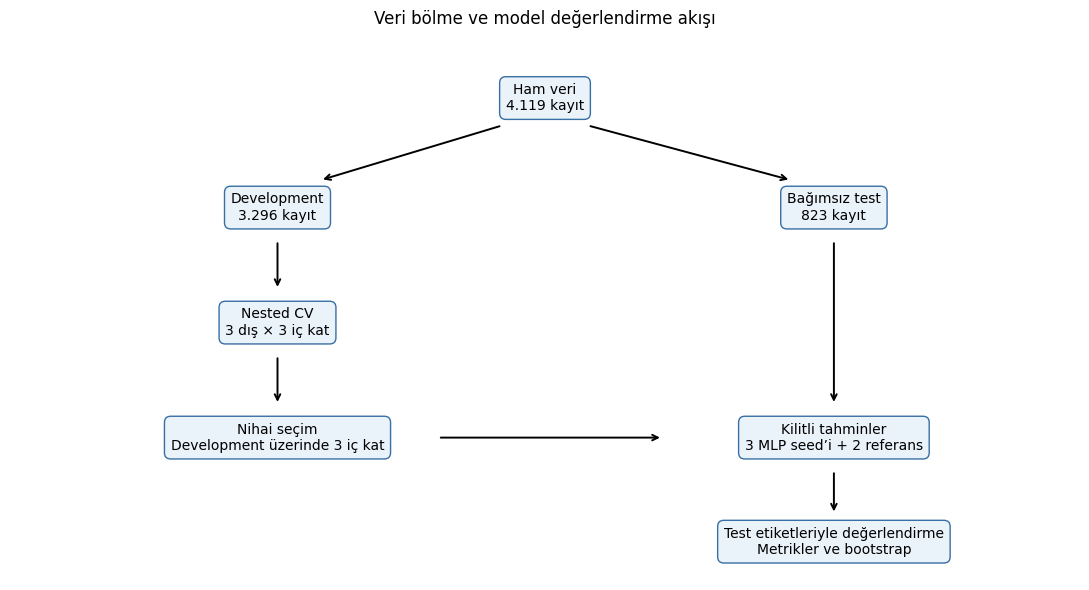

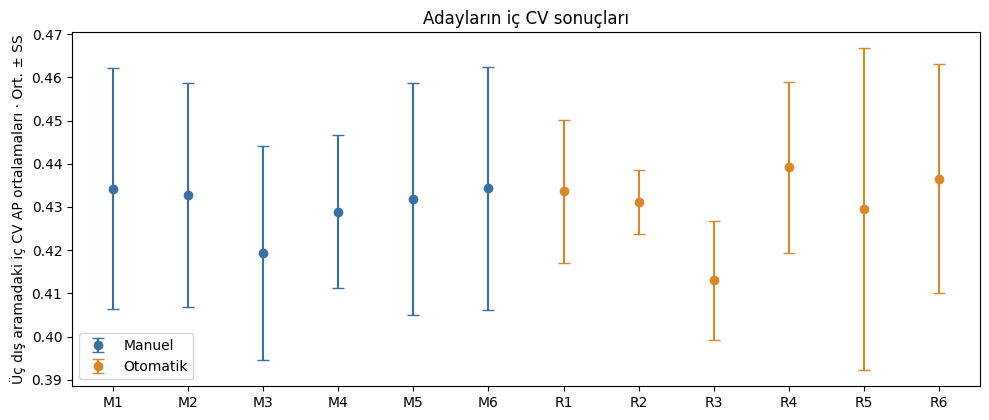

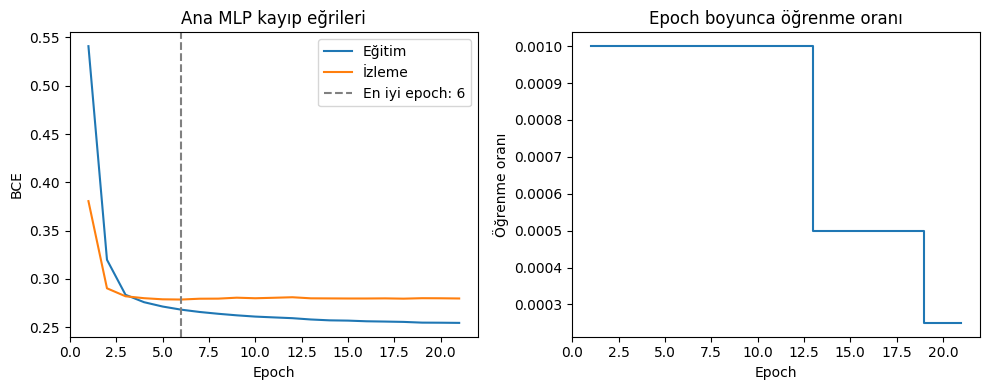

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path("/content")
figures_dir = root / "figures"
figures_dir.mkdir(exist_ok=True)


def read_result(filename):
    path = root / "results" / filename
    return pd.read_csv(path if path.is_file() else root / filename)


def save_report_figure(fig, name):
    fig.tight_layout()
    fig.savefig(figures_dir / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(figures_dir / f"{name}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)


fig, ax = plt.subplots(figsize=(11, 6))
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis("off")

boxes = [
    (0.50, 0.88, "Ham veri\n4.119 kayıt"),
    (0.25, 0.68, "Development\n3.296 kayıt"),
    (0.77, 0.68, "Bağımsız test\n823 kayıt"),
    (0.25, 0.47, "Nested CV\n3 dış × 3 iç kat"),
    (0.25, 0.26, "Nihai seçim\nDevelopment üzerinde 3 iç kat"),
    (0.77, 0.26, "Kilitli tahminler\n3 MLP seed’i + 2 referans"),
    (0.77, 0.07, "Test etiketleriyle değerlendirme\nMetrikler ve bootstrap"),
]

for start, end in [
    ((0.46, 0.83), (0.29, 0.73)),
    ((0.54, 0.83), (0.73, 0.73)),
    ((0.25, 0.62), (0.25, 0.53)),
    ((0.25, 0.41), (0.25, 0.32)),
    ((0.40, 0.26), (0.61, 0.26)),
    ((0.77, 0.62), (0.77, 0.32)),
    ((0.77, 0.20), (0.77, 0.12)),
]:
    ax.annotate("", xy=end, xytext=start, arrowprops={"arrowstyle": "->", "lw": 1.4})

for x, y, label in boxes:
    ax.text(
        x, y, label, ha="center", va="center", fontsize=10,
        bbox={"boxstyle": "round,pad=0.45", "facecolor": "#EAF2FA",
              "edgecolor": "#386FA4"},
    )

ax.set_title("Veri bölme ve model değerlendirme akışı")
save_report_figure(fig, "evaluation_workflow")

search_results = pd.concat([
    read_result("manual_search_results.csv"),
    read_result("random_search_results.csv"),
], ignore_index=True)

candidate_ids = [f"M{i}" for i in range(1, 7)] + [f"R{i}" for i in range(1, 7)]
search_plot = (
    search_results.groupby("candidate")["mean_ap"]
    .agg(["mean", "std"])
    .reindex(candidate_ids)
)

fig, ax = plt.subplots(figsize=(10, 4.3))
positions = np.arange(len(search_plot))

for start, stop, color, label in [
    (0, 6, "#386FA4", "Manuel"),
    (6, 12, "#D88729", "Otomatik"),
]:
    subset = search_plot.iloc[start:stop]
    ax.errorbar(
        positions[start:stop], subset["mean"], yerr=subset["std"],
        fmt="o", capsize=4, color=color, label=label,
    )

ax.set_xticks(positions, search_plot.index)
ax.set(
    title="Adayların iç CV sonuçları",
    ylabel="Üç dış aramadaki iç CV AP ortalamaları · Ort. ± SS",
)
ax.legend()
save_report_figure(fig, "candidate_search_comparison")

history = read_result("final_training_epochs.csv")
primary_history = history.loc[history["model"].eq("mlp_primary")].sort_values("epoch")
best_epoch = int(primary_history.loc[primary_history["monitor_bce"].idxmin(), "epoch"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(primary_history["epoch"], primary_history["train_bce"], label="Eğitim")
axes[0].plot(primary_history["epoch"], primary_history["monitor_bce"], label="İzleme")
axes[0].axvline(best_epoch, linestyle="--", color="gray", label=f"En iyi epoch: {best_epoch}")
axes[0].set(title="Ana MLP kayıp eğrileri", xlabel="Epoch", ylabel="BCE")
axes[0].legend()

axes[1].step(primary_history["epoch"], primary_history["learning_rate"], where="post")
axes[1].set(title="Epoch boyunca öğrenme oranı", xlabel="Epoch", ylabel="Öğrenme oranı")
axes[1].ticklabel_format(axis="y", style="plain")

save_report_figure(fig, "primary_training_curves")